# 第6章　銀河相互作用を調べる
**完成版 / v2.6**

「任意演習」のセルは、省略しても標準結果を保存できます。演習結果は別の `exercise_validation.json` に保存します。条件を変えたらカーネルを再起動し、上から実行し直してください。

第5章のモデル・関数を再利用し、回転方向、近点距離、質量比を別々の系列で変更します。
本章は第5章のKDKモデルを使い、条件を一つずつ変える比較実験に集中します。
PDFが説明の正本、このNotebookが実装・数値実験の正本です。下の既習関数も含むので単独で実行できます。
**実行：** カーネルを再起動して上から実行してください。NumPyとMatplotlibを使います。
データと図は `output/chap06/data/`, `output/chap06/figures/` に保存します。
比較実験・刻み試験を含むので、第5章の標準計算1回より計算量が増えます。
本章の比較系列・判定指標は教材用に設定したもので、観測銀河の定量的な再現ではありません。

In [1]:
from pathlib import Path
from time import perf_counter
import json
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd() / "output" / "chap06"
ROOT.mkdir(parents=True, exist_ok=True)
FIGDIR, DATADIR = ROOT / "figures", ROOT / "data"
FIGDIR.mkdir(exist_ok=True)
DATADIR.mkdir(exist_ok=True)

# 標準結果と任意演習の結果を分けて保存します。上から再実行すると登録を初期化します。
exercise_results = {}


def save_exercise_results():
    def json_value(value):
        if isinstance(value, np.ndarray):
            return value.tolist()
        if isinstance(value, np.generic):
            return value.item()
        if isinstance(value, dict):
            return {key: json_value(item) for key, item in value.items()}
        if isinstance(value, (list, tuple)):
            return [json_value(item) for item in value]
        return value
    record = {"status": "completed" if exercise_results else "not_run", "results": json_value(exercise_results)}
    _ = (DATADIR / "exercise_validation.json").write_text(json.dumps(record, ensure_ascii=False, indent=2), encoding="utf-8")


save_exercise_results()
IN_NOTEBOOK = "get_ipython" in globals()
MAKE_ANIMATION = IN_NOTEBOOK
if IN_NOTEBOOK:
    get_ipython().run_line_magic("matplotlib", "inline")
BLUE, VERMILLION, GREEN, GRAY = "#0072B2", "#D55E00", "#009E73", "#777777"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white"})
KM_S_TO_KPC_GYR = 1.0227121650537077
G = 4.30091e-6 * KM_S_TO_KPC_GYR**2


def save_figure(fig, name):
    fig.savefig(FIGDIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGDIR / f"{name}.png", dpi=160, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)


def to_json(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, dict):
        return {str(k): to_json(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_json(v) for v in value]
    return value

## 1. 第5章で学んだ部品（復習）
以下の4セルは、入力確認、円盤生成、重力・初期条件、KDK・診断です。
定義は第5章のコードからそのまま再利用しています。新しい算法を隠したライブラリではありません。
`b` は中心間の有効長さ、`scales` は星が受けるPlummer場のスケール長です。
本章の基本比較では $a_1=a_2=b=3$ kpc を保ちます。

In [2]:
def check_positive(value, name):
    if isinstance(value, (bool, np.bool_)) or not np.isscalar(value) or not np.isfinite(value) or value <= 0.0:
        raise ValueError(f"{name} must be finite and positive.")


def check_integer(value, name):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < 1:
        raise ValueError(f"{name} must be a positive integer.")


def check_model(masses, scales, b):
    masses, scales = np.asarray(masses, dtype=float), np.asarray(scales, dtype=float)
    for values in (masses, scales):
        if values.shape != (2,) or not np.all(np.isfinite(values)) or np.any(values <= 0.0):
            raise ValueError("Two positive finite masses and two positive Plummer scales are required.")
    if not np.isfinite(b) or b < 0.0:
        raise ValueError("The effective center softening b must be finite and nonnegative.")
    return masses, scales


def check_grid(x, values):
    x, values = np.asarray(x, dtype=float), np.asarray(values, dtype=float)
    if x.ndim != 1 or x.size < 2 or values.shape != x.shape:
        raise ValueError("Nodes and values must be equal-length 1D arrays.")
    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(values)) or np.any(np.diff(x) <= 0.0):
        raise ValueError("Use finite values and strictly increasing nodes.")
    return x, values


def cumulative_trapezoid(x, values):
    x, values = check_grid(x, values)
    integral = np.zeros_like(x)
    for j in range(len(x) - 1):
        integral[j + 1] = integral[j] + 0.5 * (values[j] + values[j + 1]) * (x[j + 1] - x[j])
    return integral


def build_radial_cdf(rd, rmax, n_panels):
    check_positive(rd, "rd")
    check_positive(rmax, "rmax")
    check_integer(n_panels, "n_panels")
    nodes = np.linspace(0.0, rmax, n_panels + 1)
    integral = cumulative_trapezoid(nodes, nodes * np.exp(-nodes / rd))
    if not np.isfinite(integral[-1]) or integral[-1] <= 0.0:
        raise ValueError("The CDF normalization must be finite and positive.")
    cdf = integral / integral[-1]
    if np.any(np.diff(cdf) <= 0.0):
        raise ValueError("The inverse CDF needs strictly increasing values.")
    return nodes, cdf


def circular_speed_plummer(radius, mass, a):
    radius = np.asarray(radius, dtype=float)
    return np.sqrt(G * mass * radius**2 / (radius**2 + a**2)**1.5)


def make_disk(n_particles, mass, a, rd, rmax, spin, rng, n_panels=4096):
    check_integer(n_particles, "n_particles")
    check_positive(mass, "mass")
    check_positive(a, "a")
    if isinstance(spin, (bool, np.bool_)) or spin not in (-1, +1):
        raise ValueError("spin must be +1 or -1.")
    nodes, values = build_radial_cdf(rd, rmax, n_panels)
    uniform = rng.random((n_particles, 2))
    radius = np.interp(uniform[:, 0], values, nodes)
    phi = 2.0 * np.pi * uniform[:, 1]
    vc = circular_speed_plummer(radius, mass, a)
    pos = np.column_stack((radius * np.cos(phi), radius * np.sin(phi)))
    vel = spin * np.column_stack((-vc * np.sin(phi), vc * np.cos(phi)))
    return np.column_stack((pos, vel)), radius, phi

In [3]:
def acceleration_plummer(pos, center, mass, a):
    """任意の中心を持つPlummer場。posは(N, 2)、centerは(2,)です。"""
    relative = pos - center
    radius2 = np.sum(relative**2, axis=1)
    return -G * mass * relative / (radius2 + a**2)[:, None]**1.5


def acceleration_centers(pos, masses, b):
    """共通のbを使う有効対ポテンシャルから、二つの加速度を返します。"""
    dr = pos[1] - pos[0]
    denom2 = np.dot(dr, dr) + b**2
    if not np.isfinite(denom2) or denom2 <= 0.0:
        raise ValueError("The effective force denominator must be positive and finite.")
    common = G * dr / denom2**1.5
    return np.array([masses[1] * common, -masses[0] * common])


def acceleration_system(pos, masses, scales, b):
    """先頭2行は銀河中心、それ以外は質量ゼロのテスト粒子です。"""
    acc = np.empty_like(pos)
    acc[:2] = acceleration_centers(pos[:2], masses, b)
    acc[2:] = acceleration_plummer(pos[2:], pos[0], masses[0], scales[0])
    acc[2:] += acceleration_plummer(pos[2:], pos[1], masses[1], scales[1])
    return acc


def make_zero_energy_encounter(masses, d_start, d_peri, b):
    masses = np.asarray(masses, dtype=float)
    check_model(masses, np.ones(2), b)
    if not (np.isfinite(d_start) and np.isfinite(d_peri) and 0.0 < d_peri < d_start):
        raise ValueError("Require finite distances with 0 < d_peri < d_start.")
    mtot = np.sum(masses)
    mu = G * mtot
    h = np.sqrt(2.0 * mu * d_peri**2 / np.sqrt(d_peri**2 + b**2))
    vt = h / d_start
    vr2 = 2.0 * mu / np.sqrt(d_start**2 + b**2) - vt**2
    if vr2 <= 0.0:
        raise ValueError("The incoming radial speed must be real and nonzero.")
    relative_velocity = np.array([-np.sqrt(vr2), vt])
    separation = np.array([d_start, 0.0])
    weights = np.array([-masses[1], masses[0]]) / mtot
    pos = weights[:, None] * separation
    vel = weights[:, None] * relative_velocity
    return np.column_stack((pos, vel))


def place_disk(local_state, center_state):
    """局所の位置と速度を慣性系へ移します。入力を上書きしません。"""
    placed = local_state.copy()
    placed[:, :2] += center_state[:2]
    placed[:, 2:] += center_state[2:]
    return placed


def make_initial_state(masses, scales, rds, rmaxs, counts, spins,
                       d_start, d_peri, b, seed, n_cdf=4096):
    check_model(masses, scales, b)
    for values in (rds, rmaxs, counts, spins):
        if np.shape(values) != (2,):
            raise ValueError("Each disk parameter array must have two entries.")
    centers = make_zero_energy_encounter(masses, d_start, d_peri, b)
    rng = np.random.default_rng(seed)
    disks, radii = [], []
    for k in range(2):
        local, radius, _ = make_disk(counts[k], masses[k], scales[k], rds[k], rmaxs[k],
                                     spins[k], rng, n_cdf)
        disks.append(place_disk(local, centers[k]))
        radii.append(radius)
    state0 = np.vstack((centers, disks[0], disks[1]))
    origin = np.repeat(np.arange(2), counts)
    return state0, origin, np.concatenate(radii)

In [4]:
def prepare_history(state0, t_end, n_steps, save_every):
    check_positive(t_end, "t_end")
    check_integer(n_steps, "n_steps")
    check_integer(save_every, "save_every")
    state = np.array(state0, dtype=float, copy=True)
    if state.ndim != 2 or state.shape[1] != 4 or len(state) < 2 or not np.all(np.isfinite(state)):
        raise ValueError("state0 must be finite, have shape (N+2, 4), and include two centers.")
    saved_steps = np.arange(0, n_steps + 1, save_every)
    if saved_steps[-1] != n_steps:
        saved_steps = np.append(saved_steps, n_steps)
    dt = t_end / n_steps
    times = saved_steps * dt
    history = np.empty((len(saved_steps), len(state), 4))
    history[0] = state
    return state, saved_steps, times, history, dt


def leapfrog_step(acceleration, pos, vel, acc, dt, masses, scales, b):
    vel_half = vel + 0.5 * dt * acc
    pos_new = pos + dt * vel_half
    acc_new = acceleration(pos_new, masses, scales, b)
    vel_new = vel_half + 0.5 * dt * acc_new
    return pos_new, vel_new, acc_new


def integrate_leapfrog(acceleration, state0, t_end, n_steps, masses, scales, b, save_every=10):
    masses, scales = check_model(masses, scales, b)
    state, saved_steps, times, history, dt = prepare_history(state0, t_end, n_steps, save_every)
    pos, vel = state[:, :2].copy(), state[:, 2:].copy()
    acc = acceleration(pos, masses, scales, b)
    center_times = np.arange(n_steps + 1) * dt
    center_history = np.empty((n_steps + 1, 2, 4))
    center_history[0] = state[:2]
    output_index = 1
    for n in range(n_steps):
        pos, vel, acc = leapfrog_step(acceleration, pos, vel, acc, dt, masses, scales, b)
        if not np.all(np.isfinite(pos)) or not np.all(np.isfinite(vel)):
            raise FloatingPointError("Non-finite state; check the model and time step.")
        center_history[n + 1] = np.column_stack((pos[:2], vel[:2]))
        if n + 1 == saved_steps[output_index]:
            history[output_index] = np.column_stack((pos, vel))
            output_index += 1
    return times, history, center_times, center_history

In [5]:
def center_diagnostics(center_history, masses, b):
    pos, vel = center_history[:, :, :2], center_history[:, :, 2:]
    dr, dv = pos[:, 1] - pos[:, 0], vel[:, 1] - vel[:, 0]
    separation = np.linalg.norm(dr, axis=1)
    kinetic = 0.5 * np.sum(masses[None, :] * np.sum(vel**2, axis=2), axis=1)
    potential = -G * masses[0] * masses[1] / np.sqrt(separation**2 + b**2)
    momentum = np.sum(masses[None, :, None] * vel, axis=1)
    r_cm = np.sum(masses[None, :, None] * pos, axis=1) / np.sum(masses)
    cross = pos[:, :, 0] * vel[:, :, 1] - pos[:, :, 1] * vel[:, :, 0]
    angular = np.sum(masses[None, :] * cross, axis=1)
    return {"D": separation, "dr": dr, "dv": dv, "E": kinetic + potential,
            "L": angular, "P": momentum, "Rcm": r_cm}


def center_errors(times, center_history, masses, b):
    d = center_diagnostics(center_history, masses, b)
    d0 = d["D"][0]
    vscale = np.sqrt(G * np.sum(masses) / d0)
    escale = G * masses[0] * masses[1] / np.sqrt(d0**2 + b**2)
    pscale = np.sum(masses) * vscale
    lscale = masses[0] * masses[1] / np.sum(masses) * d0 * vscale
    cm_exact = d["Rcm"][0] + times[:, None] * d["P"][0] / np.sum(masses)
    return np.array([np.max(np.abs(d["E"] - d["E"][0])) / escale,
                     np.max(np.abs(d["L"] - d["L"][0])) / lscale,
                     np.max(np.linalg.norm(d["P"] - d["P"][0], axis=1)) / pscale,
                     np.max(np.linalg.norm(d["Rcm"] - cm_exact, axis=1)) / d0])


def origin_radii(history, origin):
    parent_centers = history[:, origin, :2]
    return np.linalg.norm(history[:, 2:, :2] - parent_centers, axis=2)


def outer_fractions(history, origin, threshold):
    radius = origin_radii(history, origin)
    fractions = np.empty((len(history), 2))
    for k in range(2):
        selected = origin == k
        if not np.any(selected):
            raise ValueError("Both origin groups must contain test particles.")
        fractions[:, k] = np.mean(radius[:, selected] > threshold, axis=1)
    return fractions

## 2. 比較の設計と測定時刻
出身中心から30 kpcより遠い粒子割合 $f_k$ を、第5章と同じ定義で測ります。
近点通過時刻 $t_{\rm p}$ は毎ステップの中心履歴から求めます。
$\tau=t-t_{\rm p}$ とし、比較表は $\tau=0.20$ Gyr に最も近い保存時刻を使います。
これは補間した厳密な同時刻ではありません。実際に使った $t,\tau$ も記録します。
粒子の出身ラベルは固定し、閾値も系列内で変えません。

In [6]:
base_config = dict(masses=np.array([1e11, 1e11]), scales=np.array([3.0, 3.0]), b=3.0,
                   rds=np.array([3.0, 3.0]), rmaxs=np.array([15.0, 15.0]),
                   counts=np.array([1000, 1000]), spins=np.array([1, 1]),
                   d_start=60.0, d_peri=8.0, seed=42, n_cdf=4096)
t_end, n_steps, save_every = 0.60, 12000, 40
threshold, tau_target = 30.0, 0.20  # [kpc], [Gyr]


def aligned_index(times, center_times, center_history, tau_target):
    separation = np.linalg.norm(center_history[:, 1, :2] - center_history[:, 0, :2], axis=1)
    i_peri = int(np.argmin(separation))
    if i_peri == 0 or i_peri == len(center_times) - 1:
        raise ValueError("An interior pericenter is required for this comparison.")
    t_peri = center_times[i_peri]
    target = t_peri + tau_target
    if not times[0] <= target <= times[-1]:
        raise ValueError("The requested post-pericenter epoch is outside the stored range.")
    ### BEGIN SOLUTION
    j = int(np.argmin(np.abs(times - target)))
    return j, t_peri, separation[i_peri], times[j] - t_peri
    ### END SOLUTION


def run_case(config, n_steps=12000, save_every=40):
    initial, origin, radii = make_initial_state(**config)
    args = (config["masses"], config["scales"], config["b"])
    times, history, ct, ch = integrate_leapfrog(acceleration_system, initial, t_end, n_steps, *args, save_every)
    j, t_peri, d_min, tau_used = aligned_index(times, ct, ch, tau_target)
    fractions = outer_fractions(history, origin, threshold)
    return dict(config=config, initial=initial, origin=origin, radii=radii, times=times,
                history=history, center_times=ct, center_history=ch, fractions=fractions,
                index=j, t_peri=t_peri, d_min=d_min, tau_used=tau_used,
                errors=center_errors(ct, ch, config["masses"], config["b"]))

start = perf_counter()
runs = {"PP": run_case(base_config)}
base = runs["PP"]
print("Baseline: final outer fractions =", base["fractions"][-1])
print("Baseline: t_peri, t_used, tau_used =", base["t_peri"], base["times"][base["index"]], base["tau_used"])

Baseline: final outer fractions = [0.425 0.432]
Baseline: t_peri, t_used, tau_used = 0.2699 0.47 0.2001


## 3. 円盤2の内部回転だけを反転する
軌道の角運動量は正です。円盤2だけをretrogradeにします。
中心の並進速度を反転するのではなく、中心に対する内部速度だけを変えます。
同じseedと粒子数で初期値を再生成する方法が、その反転と一致することも検証します。

PP final: [0.425 0.432] ; PR final: [0.425 0.065]


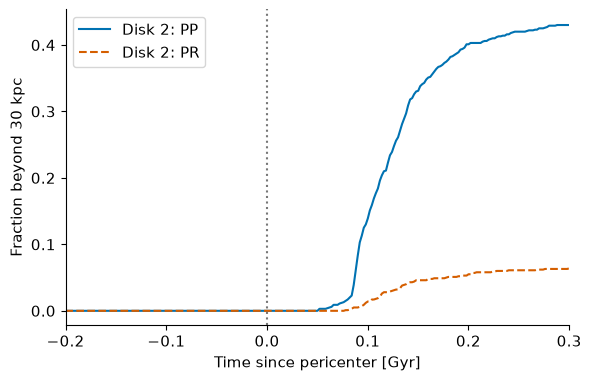

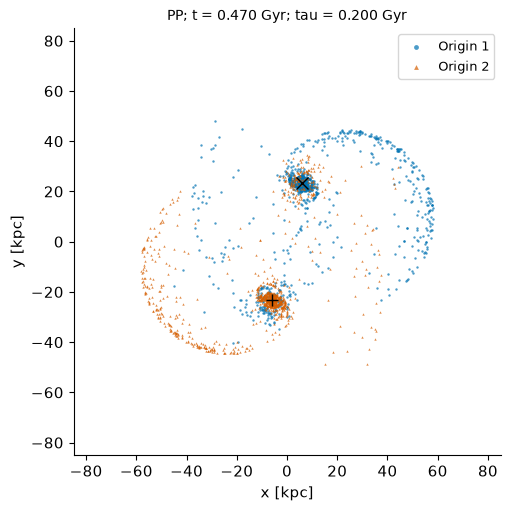

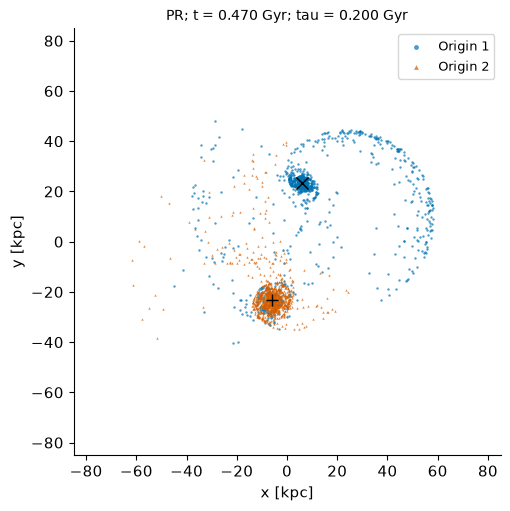

In [7]:
retro_config = dict(base_config, spins=np.array([1, -1]))
runs["PR"] = run_case(retro_config)
retro = runs["PR"]
rows2 = 2 + np.flatnonzero(base["origin"] == 1)
manual = base["initial"].copy()
### BEGIN SOLUTION
manual[rows2, 2:] = 2.0 * manual[1, 2:] - manual[rows2, 2:]
### END SOLUTION
assert np.allclose(manual, retro["initial"], rtol=0.0, atol=1e-12)
assert np.array_equal(base["center_history"], retro["center_history"])
rows1 = 2 + np.flatnonzero(base["origin"] == 0)
assert np.array_equal(base["history"][:, rows1], retro["history"][:, rows1])

print("PP final:", base["fractions"][-1], "; PR final:", retro["fractions"][-1])
fig, ax = plt.subplots(figsize=(5.8, 3.7), layout="constrained")
for key, color, ls in [("PP", BLUE, "-"), ("PR", VERMILLION, "--")]:
    run = runs[key]
    ax.plot(run["times"] - run["t_peri"], run["fractions"][:, 1], color=color, ls=ls, label=f"Disk 2: {key}")
ax.axvline(0.0, color=GRAY, ls=":")
ax.set(xlabel="Time since pericenter [Gyr]", ylabel="Fraction beyond 30 kpc", xlim=(-0.20, 0.30))
ax.legend()
save_figure(fig, "ch06_spin_fraction")


def plot_comparison_snapshot(run, name):
    j, origin = run["index"], run["origin"]
    state = run["history"][j]
    fig, ax = plt.subplots(figsize=(5.3, 5.0), layout="constrained")
    for k, color, marker in [(0, BLUE, "o"), (1, VERMILLION, "^")]:
        xy = state[2 + np.flatnonzero(origin == k), :2]
        ax.scatter(xy[:, 0], xy[:, 1], s=3, color=color, marker=marker, alpha=0.7, linewidths=0, label=f"Origin {k+1}")
    ax.plot(state[0, 0], state[0, 1], "x", color="black", ms=8)
    ax.plot(state[1, 0], state[1, 1], "+", color="black", ms=9)
    ax.set(xlabel="x [kpc]", ylabel="y [kpc]", xlim=(-85, 85), ylim=(-85, 85))
    ax.set_title(f"{name}; t = {run['times'][j]:.3f} Gyr; tau = {run['tau_used']:.3f} Gyr", fontsize=10)
    ax.set_aspect("equal")
    ax.legend(loc="upper right", fontsize=9, markerscale=2)
    return fig

save_figure(plot_comparison_snapshot(base, "PP"), "ch06_pp")
save_figure(plot_comparison_snapshot(retro, "PR"), "ch06_pr")

## 4. 近点距離の系列
$D_{\rm p}=5,8,12$ kpcを比較します。$D_0$、質量、円盤、回転方向、seedは固定します。
各近点について、中心軌道のエネルギーが0になる初期速度を作り直します。
近点だけを書き換えて初期速度を前のまま使う方法ではありません。

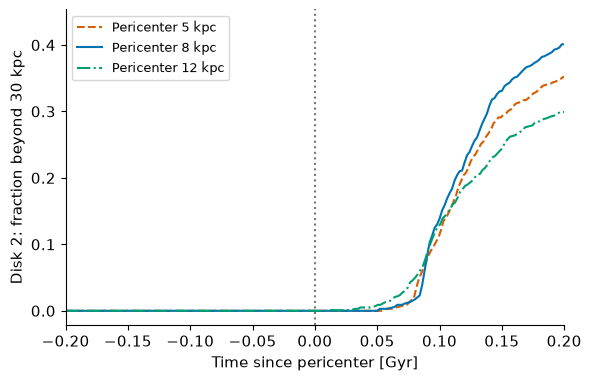

In [8]:
for d_peri in [5.0, 12.0]:
    ### BEGIN SOLUTION
    config = dict(base_config, d_peri=d_peri)
    runs[f"P{d_peri:g}"] = run_case(config)
    ### END SOLUTION
fig, ax = plt.subplots(figsize=(5.8, 3.7), layout="constrained")
for key, color, ls in [("P5", VERMILLION, "--"), ("PP", BLUE, "-"), ("P12", GREEN, "-.")]:
    run = runs[key]
    ax.plot(run["times"] - run["t_peri"], run["fractions"][:, 1], color=color, ls=ls, label=f"Pericenter {run['config']['d_peri']:g} kpc")
ax.axvline(0.0, color=GRAY, ls=":")
ax.set(xlabel="Time since pericenter [Gyr]", ylabel="Disk 2: fraction beyond 30 kpc", xlim=(-0.20, 0.20))
ax.legend(fontsize=9)
save_figure(fig, "ch06_pericenter_fraction")

## 5. 質量比の系列
$M_1=10^{11}M_\odot$を固定し、$q=M_2/M_1=1,0.5,0.1$を比較します。
全質量は固定していません。中心の初期速度と円盤2の円運動速度を作り直します。
$a_1=a_2=b$と円盤の大きさは固定する教材用の比較で、現実の銀河の質量–サイズ関係ではありません。
各円盤1000粒子のままです。粒子数比は質量比を意味しません。

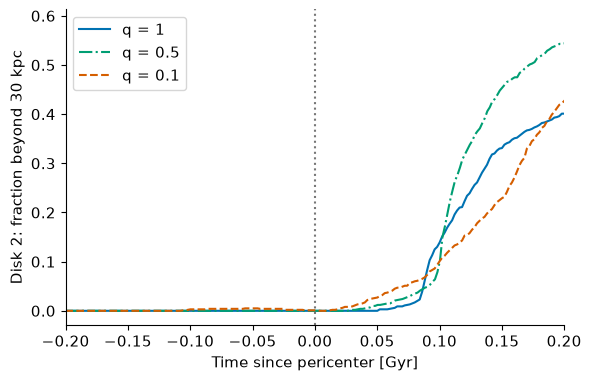

PP    : tp=0.269900; tau=0.200100; f=[0.39  0.401]
PR    : tp=0.269900; tau=0.200100; f=[0.39  0.055]
P5    : tp=0.254700; tau=0.199300; f=[0.331 0.352]
P12   : tp=0.287500; tau=0.200500; f=[0.304 0.299]
Q0.5  : tp=0.311650; tau=0.200350; f=[0.225 0.544]
Q0.1  : tp=0.363900; tau=0.200100; f=[0.    0.427]
Six standard runs and figures: 15.39 s in this environment


In [9]:
for q in [0.5, 0.1]:
    config = dict(base_config, masses=np.array([1.0e11, q * 1.0e11]))
    runs[f"Q{q:g}"] = run_case(config)
fig, ax = plt.subplots(figsize=(5.8, 3.7), layout="constrained")
for key, color, ls in [("PP", BLUE, "-"), ("Q0.5", GREEN, "-."), ("Q0.1", VERMILLION, "--")]:
    run = runs[key]
    q = run["config"]["masses"][1] / run["config"]["masses"][0]
    ax.plot(run["times"] - run["t_peri"], run["fractions"][:, 1], color=color, ls=ls, label=f"q = {q:g}")
ax.axvline(0.0, color=GRAY, ls=":")
ax.set(xlabel="Time since pericenter [Gyr]", ylabel="Disk 2: fraction beyond 30 kpc", xlim=(-0.20, 0.20))
ax.legend()
save_figure(fig, "ch06_mass_fraction")

comparison = []
for name, run in runs.items():
    cfg, j = run["config"], run["index"]
    q = cfg["masses"][1] / cfg["masses"][0]
    row = dict(name=name, q=q, d_peri=cfg["d_peri"], d_min=run["d_min"], t_peri=run["t_peri"],
               t_used=run["times"][j], tau_used=run["tau_used"], fractions=run["fractions"][j],
               fractions_final=run["fractions"][-1], center_errors=run["errors"])
    comparison.append(row)
    print(f"{name:6s}: tp={row['t_peri']:.6f}; tau={row['tau_used']:.6f}; f={row['fractions']}")
    np.savez_compressed(DATADIR / f"{name}_initial.npz", state=run["initial"], origin=run["origin"])
    indices = [0, j, len(run["times"])-1]
    np.savez_compressed(DATADIR / f"{name}_snapshots.npz", times=run["times"][indices], state=run["history"][indices], origin=run["origin"])
    np.savetxt(DATADIR / f"{name}_fractions.csv", np.column_stack((run["times"], run["times"]-run["t_peri"], run["fractions"])), delimiter=",", header="t_Gyr,tau_Gyr,f1,f2", comments="")
print(f"Six standard runs and figures: {perf_counter()-start:.2f} s in this environment")

## 6. 指標・標本・時間刻みを別々に変える
まず同じ計算結果で距離の閾値を20,30,40 kpcへ変えます。
次にseed 42,43,44についてPP–PRを対にして比較します。3例はばらつきの例示であり、誤差分布の精密推定ではありません。
最後にPP、近点5 kpc、質量比0.1を0.05/0.025 Myrで比較します。初期配列と保存時刻を一致させます。
集計指標が同じでも、個別軌道の最大差が小さいとは限りません。

In [10]:
threshold_rows = []
for cut in [20.0, 30.0, 40.0]:
    f_pp = outer_fractions(base["history"][base["index"]:base["index"]+1], base["origin"], cut)[0]
    f_pr = outer_fractions(retro["history"][retro["index"]:retro["index"]+1], retro["origin"], cut)[0]
    threshold_rows.append([cut, f_pp[1], f_pr[1], f_pp[1] - f_pr[1]])
print("Threshold check [cut, f2(PP), f2(PR), difference]:", threshold_rows)

seed_rows = [[42, base["fractions"][base["index"], 1], retro["fractions"][retro["index"], 1]]]
for seed in [43, 44]:
    pair = []
    for spins in [np.array([1, 1]), np.array([1, -1])]:
        temporary = run_case(dict(base_config, seed=seed, spins=spins))
        pair.append(temporary["fractions"][temporary["index"], 1])
    seed_rows.append([seed, *pair])
    del temporary
print("Paired seeds [seed, f2(PP), f2(PR)]:", seed_rows)

resolution_rows = []
for name in ["PP", "P5", "Q0.1"]:
    coarse = runs[name]
    cfg = coarse["config"]
    args = (cfg["masses"], cfg["scales"], cfg["b"])
    tt, hh, ct, ch = integrate_leapfrog(acceleration_system, coarse["initial"], t_end, 24000, *args, 80)
    assert np.allclose(tt, coarse["times"], rtol=0.0, atol=1e-14)
    difference = hh[:, 2:, :2] - coarse["history"][:, 2:, :2]
    max_difference = np.max(np.linalg.norm(difference, axis=2)) / cfg["rds"][0]
    rms_difference = np.sqrt(np.mean(np.sum(difference**2, axis=2))) / cfg["rds"][0]
    fine_f = outer_fractions(hh[coarse["index"]:coarse["index"]+1], coarse["origin"], threshold)[0]
    resolution_rows.append(dict(name=name, max_difference=max_difference, rms_difference=rms_difference,
                                coarse_f=coarse["fractions"][coarse["index"]], fine_f=fine_f,
                                fine_energy_error=center_errors(ct, ch, cfg["masses"], cfg["b"])[0]))
    del hh, ch, difference
print("Time-step check:", to_json(resolution_rows))

Threshold check [cut, f2(PP), f2(PR), difference]: [[20.0, np.float64(0.447), np.float64(0.092), np.float64(0.355)], [30.0, np.float64(0.401), np.float64(0.055), np.float64(0.34600000000000003)], [40.0, np.float64(0.314), np.float64(0.038), np.float64(0.276)]]


Paired seeds [seed, f2(PP), f2(PR)]: [[42, np.float64(0.401), np.float64(0.055)], [43, np.float64(0.409), np.float64(0.06)], [44, np.float64(0.415), np.float64(0.054)]]


Time-step check: [{'name': 'PP', 'max_difference': 0.016096393030073014, 'rms_difference': 0.0001668162342219451, 'coarse_f': [0.39, 0.401], 'fine_f': [0.39, 0.401], 'fine_energy_error': 8.257526370397689e-07}, {'name': 'P5', 'max_difference': 0.012521224804506216, 'rms_difference': 0.00020651000911950512, 'coarse_f': [0.331, 0.352], 'fine_f': [0.331, 0.352], 'fine_energy_error': 3.975947725428402e-06}, {'name': 'Q0.1', 'max_difference': 0.0005136149295643895, 'rms_difference': 1.1925011478929122e-05, 'coarse_f': [0.0, 0.427], 'fine_f': [0.0, 0.427], 'fine_energy_error': 4.541642076538386e-07}]


### 演習6.7：中心間の有効長さと力
ここでは軌道を変更せず、同じ距離での有効加速度と点質量加速度の比だけを調べます。
この比は中心間の並進加速度に関する量です。星への潮汐加速度差やテイル長ではありません。

In [11]:
# OPTIONAL EXERCISE: 6.7
# 任意演習：このセル全体を省略しても、標準結果の保存は実行できます。
# TODOで作る結果：softening_rows
# 正常終了時に exercise_results['6.7'] へ次のキーで登録します：softening_rows
exercise_results.pop('6.7', None)
save_exercise_results()
peri_values = np.array([5.0, 8.0, 12.0])
b_eff = base_config["b"]
### BEGIN SOLUTION
force_ratios = peri_values**3 / (peri_values**2 + b_eff**2)**1.5
### END SOLUTION
softening_rows = np.column_stack((peri_values, np.sqrt(peri_values**2 + b_eff**2), force_ratios))
print("D [kpc], effective distance [kpc], acceleration ratio:")
print(softening_rows)
exercise_results['6.7'] = {'softening_rows': softening_rows}
save_exercise_results()

D [kpc], effective distance [kpc], acceleration ratio:
[[ 5.          5.83095189  0.6305095 ]
 [ 8.          8.54400375  0.82089133]
 [12.         12.36931688  0.91307529]]


## 7. 記録と課題
**確認：** 変更した値、連動して作り直した初期値、比較時刻、指標の定義を記録してください。
**応用：** PP--PR、近点、質量比のいずれか1系列を選び、同じ表示範囲の図と$f_k$を示してください。
**最終課題：** 問い・モデル・条件・結果・検証・解釈と限界の順に短いレポートへまとめます。
このNotebookの標準値は実在の銀河の測定値ではありません。結論は採用した近似の範囲に限定します。

In [12]:
validation = dict(version="2.3", numpy_version=np.__version__, base_config=base_config,
                  t_end=t_end, n_steps=n_steps, save_every=save_every, threshold=threshold, tau_target=tau_target,
                  comparison=comparison, threshold_rows=threshold_rows, seed_rows=seed_rows, resolution=resolution_rows)
_ = (DATADIR / "validation.json").write_text(json.dumps(to_json(validation), ensure_ascii=False, indent=2), encoding="utf-8")
assert np.allclose(base["fractions"][-1], [0.425, 0.432], atol=0.002, rtol=0.0)
assert np.allclose(retro["fractions"][-1], [0.425, 0.065], atol=0.002, rtol=0.0)
print("Chapter 6 comparison runs completed. Validation and numerical tables saved in", DATADIR)

Chapter 6 comparison runs completed. Validation and numerical tables saved in output/chap06/data


## 8. 基本モデルのアニメーション
第5章の標準PPモデルを再生します。全粒子は出身の色を保ちます。
画面の再生間隔・履歴の保存間隔・数値積分の刻みは、それぞれ別です。
比較の結論は静止画と定量指標でも判断してください。

In [13]:
if MAKE_ANIMATION:
    from matplotlib.animation import FuncAnimation
    from IPython.display import HTML, display
    fig, ax = plt.subplots(figsize=(5.8, 5.3), layout="constrained")
    origin = base["origin"]
    points = []
    for k, color, marker in [(0, BLUE, "o"), (1, VERMILLION, "^")]:
        ids = 2 + np.flatnonzero(origin == k)
        sc = ax.scatter([], [], s=3, color=color, marker=marker, alpha=0.7, linewidths=0, label=f"Origin {k+1}")
        points.append((ids, sc))
    centers_plot, = ax.plot([], [], "k+", ms=9)
    title = ax.set_title("")
    ax.set(xlabel="x [kpc]", ylabel="y [kpc]", xlim=(-90, 90), ylim=(-90, 90))
    ax.set_aspect("equal")
    ax.legend(loc="upper right", fontsize=8)
    frames = np.arange(0, len(base["times"]), 3)
    def update(j):
        state = base["history"][j]
        for ids, sc in points:
            sc.set_offsets(state[ids, :2])
        centers_plot.set_data(state[:2, 0], state[:2, 1])
        title.set_text(f"PP; t = {base['times'][j]:.3f} Gyr")
        return [sc for _, sc in points] + [centers_plot, title]
    animation = FuncAnimation(fig, update, frames=frames, interval=60, blit=False)
    html = animation.to_jshtml()
    (FIGDIR / "ch06_animation.html").write_text(html, encoding="utf-8")
    plt.close(fig)
    display(HTML(html))
else:
    print("Animation is available in the completed Notebook.")

## 任意演習の実行状況を保存する
演習を省略した場合も、空の結果と `not_run` を保存して前回のファイルを更新します。

In [14]:
save_exercise_results()
print("Exercise results:", sorted(exercise_results) if exercise_results else "not run")

Exercise results: ['6.7']
